
# NFL 2026 Quarterback Performance Analysis & Machine Learning

## Project Overview

This project analyzes NFL quarterback statistics collected from ESPN using Python. The objective is to explore quarterback performance, identify statistical relationships, and develop machine learning models to estimate ESPN's Total QBR.

The project covers the complete data science workflow, from data collection and preprocessing to exploratory data analysis, feature engineering, model training, and evaluation.

## Project Objectives

1. **Data Collection:** Extract NFL quarterback statistics from ESPN using Pandas.
2. **Data Preprocessing:** Clean player names, separate team abbreviations, verify data types, and identify missing values and duplicates.
3. **Exploratory Data Analysis (EDA):** Examine descriptive statistics, distributions, correlations, and outliers.
4. **Data Visualization:** Create histograms, boxplots, heatmaps, barplots, and scatterplots to identify performance patterns.
5. **Feature Engineering:** Calculate touchdown percentage (TD_PCT) and interception percentage (INT_PCT).
6. **Feature Selection:** Select relevant passing statistics to estimate quarterback QBR.
7. **Machine Learning:** Train and compare Linear Regression and Ridge Regression models.
8. **Model Evaluation:** Evaluate performance using MAE, RMSE, R², and 5-fold cross-validation.
9. **Hyperparameter Tuning:** Use GridSearchCV to optimize Ridge Regression regularization.
10. **Model Diagnostics:** Examine residuals to identify prediction errors and potential model limitations.

## Dataset Overview

- **Source:** ESPN NFL Player Statistics
- **Season:** 2026
- **Observations:** 50 quarterbacks
- **Original Features:** 18 columns
- **Target Variable:** QBR
- **Engineered Features:** TD_PCT and INT_PCT

## Tools and Libraries

- **Python:** Data analysis and machine learning
- **Pandas:** Data collection, cleaning, and manipulation
- **NumPy:** Numerical computations
- **Matplotlib:** Data visualization
- **Seaborn:** Statistical visualization
- **Scikit-learn:** Regression modeling, cross-validation, and hyperparameter tuning

## Expected Outcomes

This project aims to:

- Identify relationships between quarterback statistics and overall performance.
- Examine how passing accuracy, efficiency, and production relate to QBR.
- Compare Linear Regression and Ridge Regression models.
- Determine whether regularization and hyperparameter tuning improve model performance.
- Evaluate prediction errors and identify opportunities for future improvements.

**Note:** The models estimate QBR using same-season statistics rather than predicting future quarterback performance.

# Loading Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Importing Dataset from a URL using Pandas

In [2]:
url = 'https://www.espn.com/nfl/stats/player'
tables = pd.read_html(url)
print(f'We have a total of {len(tables)} that we have to combine and clean.')

We have a total of 2 that we have to combine and clean.


In [3]:
# visualzing the first dataframe
tables[0].head()

,RK,Name
0,1,Jordan LoveGB
1,2,Joe BurrowCIN
2,3,Dak PrescottDAL
3,4,Matthew StaffordLAR
4,5,Kirk CousinsLV


In [4]:
# visualzing the second data frame
tables[1].head()

,POS,GP,CMP,ATT,CMP%,YDS,AVG,YDS/G,LNG,TD,INT,SACK,SYL,QBR,RTG
0,QB,9,215,341,63.0,2618,7.7,290.9,81,19,6,17,101,70.7,97.9
1,QB,8,219,296,74.0,2386,8.1,298.3,47,23,6,15,102,79.6,114.8
2,QB,9,218,336,64.9,2381,7.1,264.6,53,16,5,14,69,77.1,95.3
3,QB,9,230,346,66.5,2374,6.9,263.8,64,16,9,13,97,58.6,90.6
4,QB,9,202,315,64.1,2340,7.4,260.0,45,20,8,11,64,62.1,97.1


# Step 2: Data Preprocessing

In [5]:
# merging the dataframes together
df = pd.concat([tables[0],tables[1]],axis = 1)
df.head()

,RK,Name,POS,GP,CMP,ATT,CMP%,YDS,AVG,YDS/G,LNG,TD,INT,SACK,SYL,QBR,RTG
0,1,Jordan LoveGB,QB,9,215,341,63.0,2618,7.7,290.9,81,19,6,17,101,70.7,97.9
1,2,Joe BurrowCIN,QB,8,219,296,74.0,2386,8.1,298.3,47,23,6,15,102,79.6,114.8
2,3,Dak PrescottDAL,QB,9,218,336,64.9,2381,7.1,264.6,53,16,5,14,69,77.1,95.3
3,4,Matthew StaffordLAR,QB,9,230,346,66.5,2374,6.9,263.8,64,16,9,13,97,58.6,90.6
4,5,Kirk CousinsLV,QB,9,202,315,64.1,2340,7.4,260.0,45,20,8,11,64,62.1,97.1


In [6]:
# creatigng a new column called team 
df['TEAM'] = df['Name'].str.extract(r'([A-Z]{2,3})$')

# putting the TEAM column right after the Name column
df.insert(2,'TEAM',df.pop('TEAM'))

In [7]:
df['Name'] = df['Name'].str.replace(r'[A-Z]{2,3}$','',regex=True)


df.head(10)

,RK,Name,TEAM,POS,GP,CMP,ATT,CMP%,YDS,AVG,YDS/G,LNG,TD,INT,SACK,SYL,QBR,RTG
0,1,Jordan Love,GB,QB,9,215,341,63.0,2618,7.7,290.9,81,19,6,17,101,70.7,97.9
1,2,Joe Burrow,CIN,QB,8,219,296,74.0,2386,8.1,298.3,47,23,6,15,102,79.6,114.8
2,3,Dak Prescott,DAL,QB,9,218,336,64.9,2381,7.1,264.6,53,16,5,14,69,77.1,95.3
3,4,Matthew Stafford,LAR,QB,9,230,346,66.5,2374,6.9,263.8,64,16,9,13,97,58.6,90.6
4,5,Kirk Cousins,LV,QB,9,202,315,64.1,2340,7.4,260.0,45,20,8,11,64,62.1,97.1
5,6,Drake Maye,NE,QB,9,178,272,65.4,2282,8.4,253.6,63,18,11,20,103,73.7,96.8
6,7,C.J. Stroud,HOU,QB,8,181,282,64.2,2251,8.0,281.4,63,16,2,16,103,72.6,104.8
7,8,Bryce Young,CAR,QB,8,186,308,60.4,2197,7.1,274.6,55,16,6,26,155,64.8,91.3
8,9,Jared Goff,DET,QB,8,185,273,67.8,2134,7.8,266.8,57,15,2,19,129,58.1,106.4
9,10,Geno Smith,NYJ,QB,9,183,271,67.5,2078,7.7,230.9,60,12,3,28,236,55.0,100.5


# Step 3: Data Inspection

In [8]:
def inspect_data(df):
    df = df.copy()

    print('DataFrame Info'.center(50,'='))
    df.info()
    
    print('\n')
    print('Missing Values by Column'.center(50,'='))
    print(df.isnull().sum())
    
    print('\n')
    print('DataFrame Shape'.center(50,'='))
    print(f'This DataFrame has a total of {df.shape[0]} rows and {df.shape[1]} columns.')

    print('\n')
    print('Duplicate Rows'.center(50, '='))
    print(f'Number of Duplicate Rows: {df.duplicated().sum()}.')

inspect_data(df)

==================DataFrame Info==================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 18 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RK      50 non-null     int64  
 1   Name    50 non-null     object 
 2   TEAM    50 non-null     object 
 3   POS     50 non-null     object 
 4   GP      50 non-null     int64  
 5   CMP     50 non-null     int64  
 6   ATT     50 non-null     int64  
 7   CMP%    50 non-null     float64
 8   YDS     50 non-null     int64  
 9   AVG     50 non-null     float64
 10  YDS/G   50 non-null     float64
 11  LNG     50 non-null     int64  
 12  TD      50 non-null     int64  
 13  INT     50 non-null     int64  
 14  SACK    50 non-null     int64  
 15  SYL     50 non-null     int64  
 16  QBR     50 non-null     float64
 17  RTG     50 non-null     float64
dtypes: float64(5), int64(10), object(3)
memory usage: 7.2+ KB


=============Missing Values by Column====

# Step 4: Exploratory Data Analysis - EDA

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RK,50.0,25.500,14.577380,1.0,13.250,25.50,37.750,50.0
GP,50.0,5.860,2.725615,1.0,3.000,7.00,8.000,9.0
CMP,50.0,113.580,70.470747,4.0,42.250,122.50,177.750,230.0
ATT,50.0,177.160,108.061842,8.0,65.000,197.00,272.750,346.0
CMP%,50.0,63.114,5.947354,45.5,60.450,64.00,66.150,76.5
YDS,50.0,1257.800,799.616592,51.0,432.000,1420.00,1968.000,2618.0
AVG,50.0,6.918,1.225026,3.9,6.250,6.85,7.700,10.0
YDS/G,50.0,192.680,63.946521,25.5,148.600,196.15,248.100,298.3
LNG,50.0,50.980,17.398675,13.0,40.250,52.50,62.250,82.0
TD,50.0,8.180,6.371781,0.0,3.000,6.50,13.750,23.0


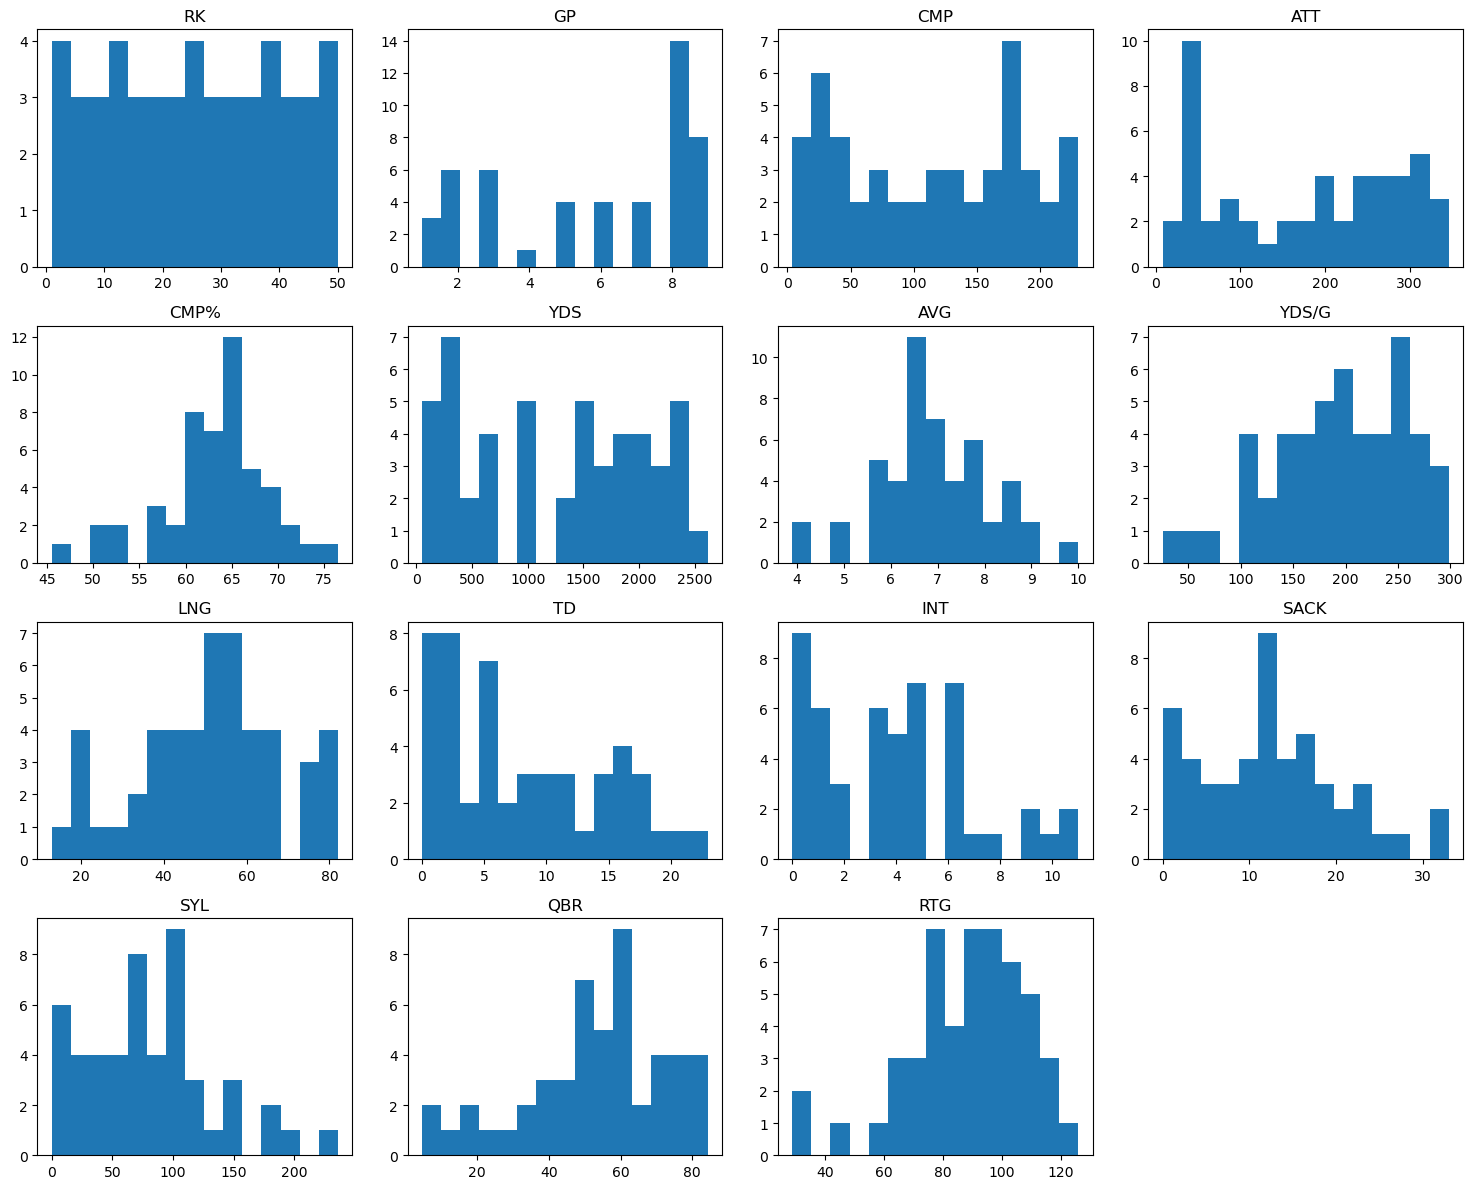

In [10]:
df.hist(figsize=(15, 12), bins=15,grid=False)
plt.tight_layout()
plt.show()

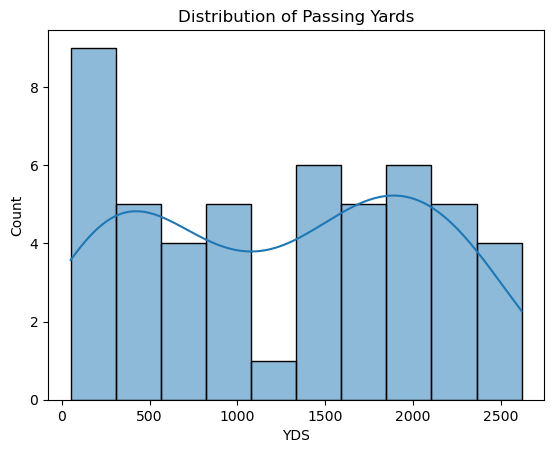

In [11]:
yards = sns.histplot(data=df, x='YDS', bins=10, kde=True)
plt.title('Distribution of Passing Yards')
plt.show()

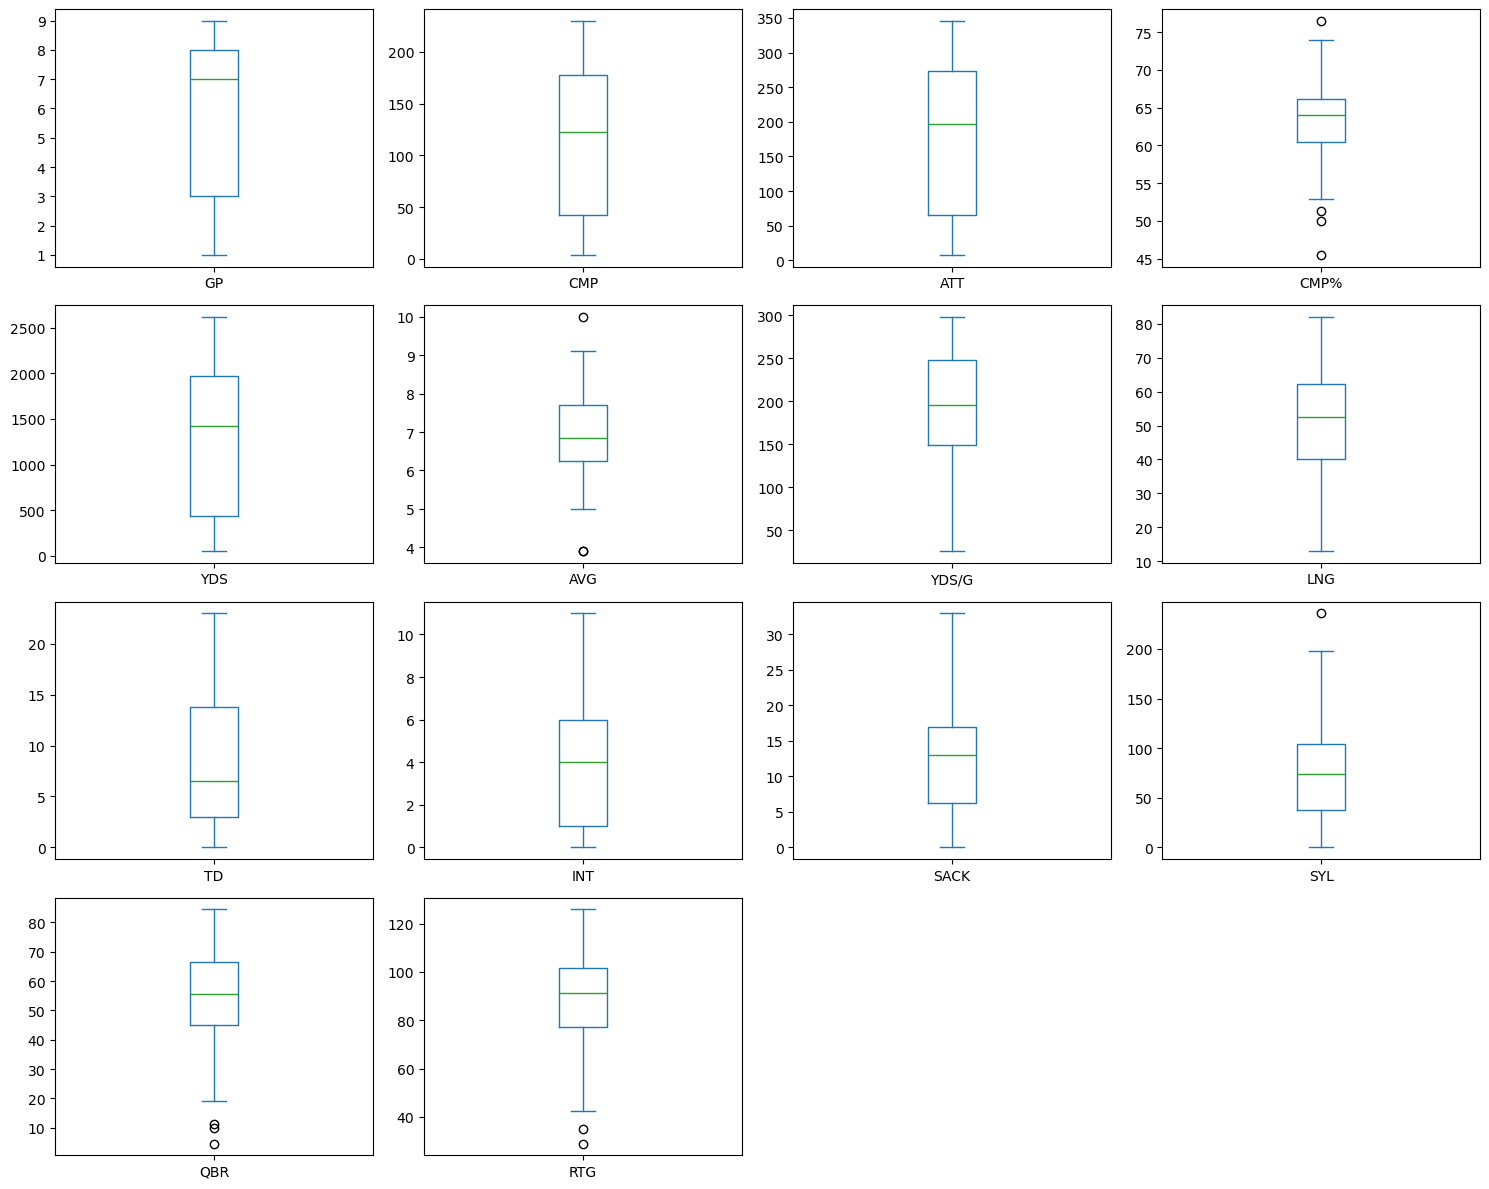

In [12]:
# looking for outliers in the DataFrame
df.drop(columns='RK').select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(4, 4),
    figsize=(15, 12),
    sharey=False)

plt.tight_layout()
plt.show()

In [13]:
# looking at specific columns that have outliers 

columns = ['CMP%', 'AVG', 'QBR']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f'\nOutliers for {col}:')
    print(outliers[['Name', 'TEAM', 'GP', col]])


Outliers for CMP%:
                 Name TEAM  GP  CMP%
43        Jaxson Dart  NYG   2  76.5
45  Athan Kaliakmanis  WSH   1  45.5
47        Joe Fagnano  BAL   2  51.3
49       Tommy DeVito   NE   2  50.0

Outliers for AVG:
             Name TEAM  GP   AVG
29  Lamar Jackson  BAL   5  10.0
47    Joe Fagnano  BAL   2   3.9
48    Jack Strand  ATL   1   3.9

Outliers for QBR:
           Name TEAM  GP   QBR
44  Cooper Rush  ATL   2   4.6
47  Joe Fagnano  BAL   2   9.9
48  Jack Strand  ATL   1  11.4


In [14]:
# creating a correlation table
corr = df.corr(numeric_only=True)
corr

,RK,GP,CMP,ATT,CMP%,YDS,AVG,YDS/G,LNG,TD,INT,SACK,SYL,QBR,RTG
RK,1.000000,-0.933029,-0.974528,-0.960529,-0.415111,-0.993332,-0.442330,-0.897804,-0.594920,-0.935225,-0.640585,-0.671363,-0.669423,-0.545262,-0.409628
GP,-0.933029,1.000000,0.951691,0.959528,0.312096,0.946323,0.341828,0.753755,0.620506,0.821707,0.728962,0.768047,0.744984,0.432345,0.288295
CMP,-0.974528,0.951691,1.000000,0.994457,0.348353,0.981858,0.294054,0.857371,0.549788,0.887675,0.694316,0.712333,0.709856,0.449068,0.305928
ATT,-0.960529,0.959528,0.994457,1.000000,0.281870,0.973165,0.248230,0.836542,0.552980,0.864423,0.721265,0.737760,0.726571,0.406390,0.255203
CMP%,-0.415111,0.312096,0.348353,0.281870,1.000000,0.360684,0.628120,0.436645,0.284205,0.395545,0.012014,0.113722,0.159012,0.755964,0.782535
YDS,-0.993332,0.946323,0.981858,0.973165,0.360684,1.000000,0.414287,0.890681,0.593427,0.928440,0.669437,0.694511,0.688163,0.506388,0.368482
AVG,-0.442330,0.341828,0.294054,0.248230,0.628120,0.414287,1.000000,0.484101,0.496868,0.461830,0.014941,0.134724,0.164543,0.703739,0.812770
YDS/G,-0.897804,0.753755,0.857371,0.836542,0.436645,0.890681,0.484101,1.000000,0.574936,0.854971,0.489066,0.565270,0.579847,0.578132,0.482727
LNG,-0.594920,0.620506,0.549788,0.552980,0.284205,0.593427,0.496868,0.574936,1.000000,0.523029,0.361835,0.451138,0.460997,0.486395,0.395436
TD,-0.935225,0.821707,0.887675,0.864423,0.395545,0.928440,0.461830,0.854971,0.523029,1.000000,0.557363,0.475242,0.483884,0.606312,0.479205


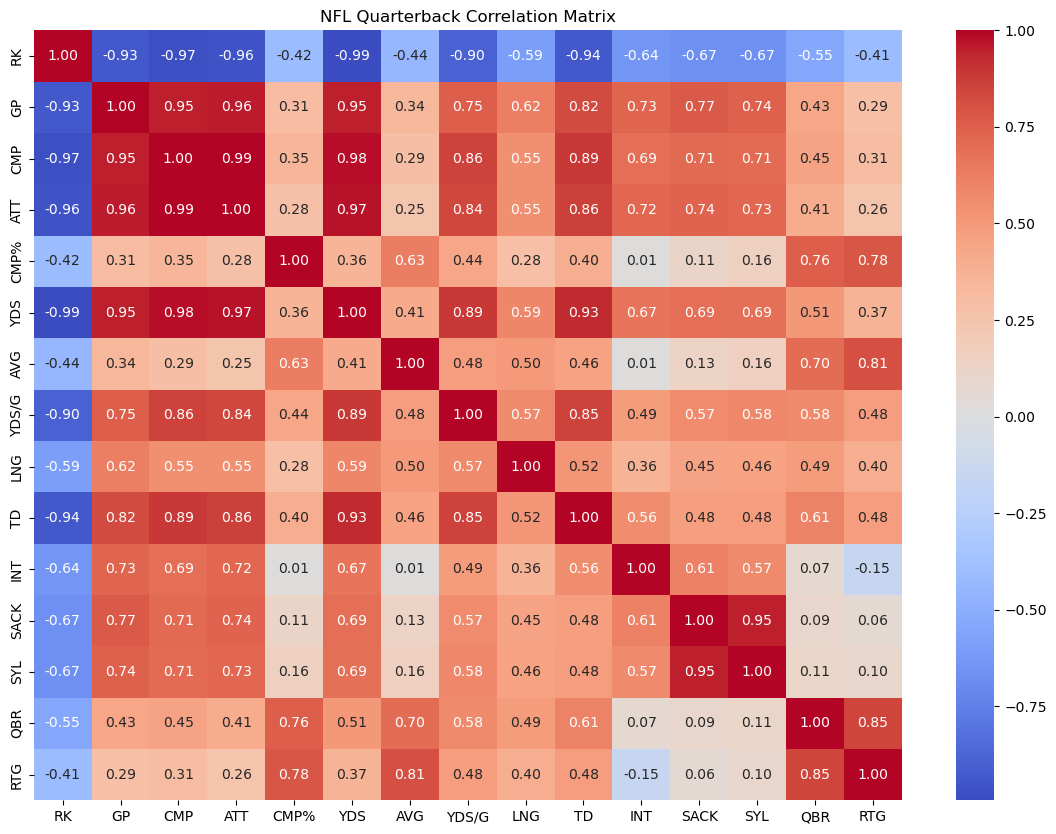

In [15]:
plt.figure(figsize=(14, 10))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('NFL Quarterback Correlation Matrix')
plt.show()

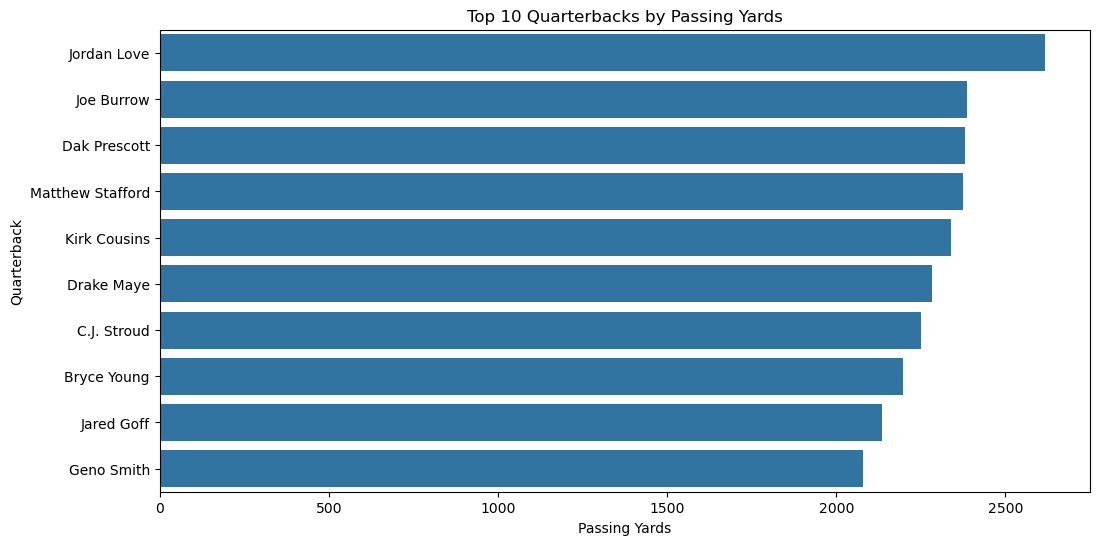

In [16]:
top10 = df.nlargest(10, 'YDS')

plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x='YDS', y='Name')

plt.title('Top 10 Quarterbacks by Passing Yards')
plt.xlabel('Passing Yards')
plt.ylabel('Quarterback')
plt.grid(False)
plt.show()

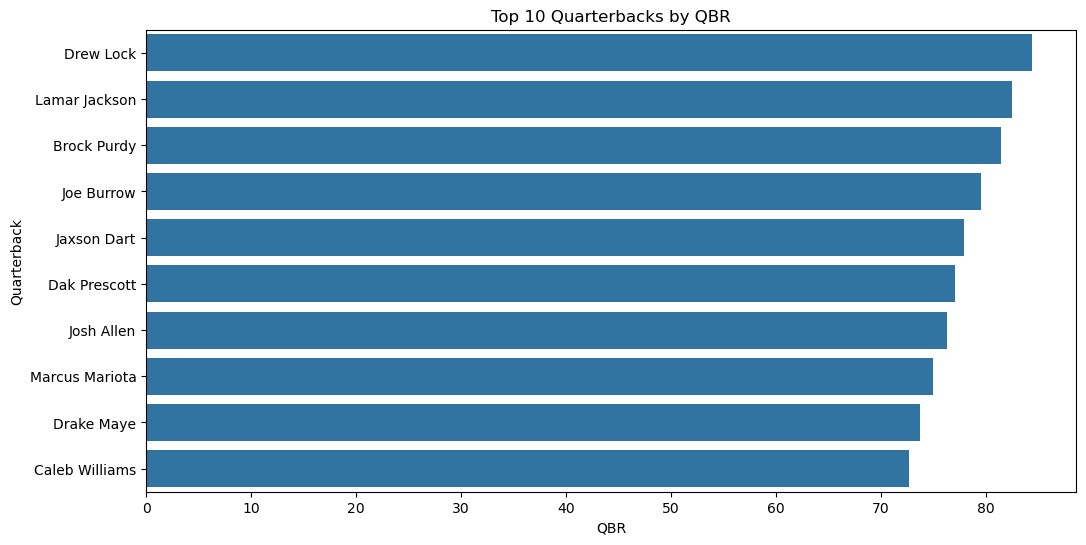

In [17]:
top10_qbr = df.nlargest(10, 'QBR')

plt.figure(figsize=(12, 6))
sns.barplot(data=top10_qbr, x='QBR', y='Name')

plt.title('Top 10 Quarterbacks by QBR')
plt.xlabel('QBR')
plt.ylabel('Quarterback')
plt.grid(False)
plt.show()

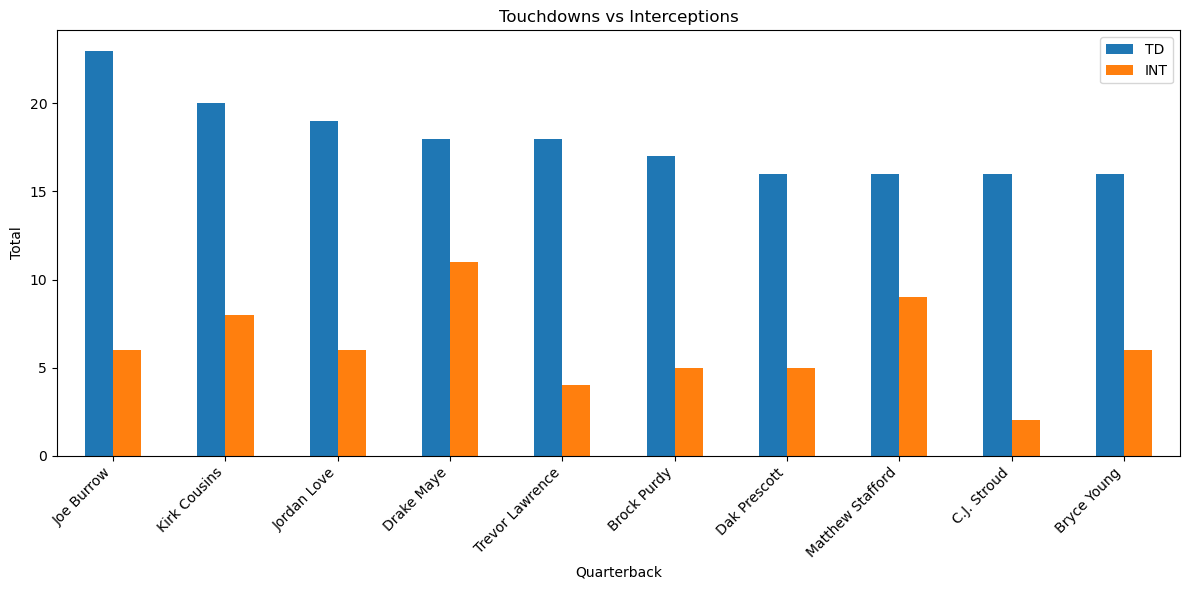

In [18]:
top10_td = df.nlargest(10, 'TD')

top10_td.plot(
    x='Name',
    y=['TD', 'INT'],
    kind='bar',
    figsize=(12, 6))

plt.title('Touchdowns vs Interceptions')
plt.xlabel('Quarterback')
plt.ylabel('Total')
plt.xticks(rotation=45, ha='right')
plt.grid(False)
plt.tight_layout()
plt.show()

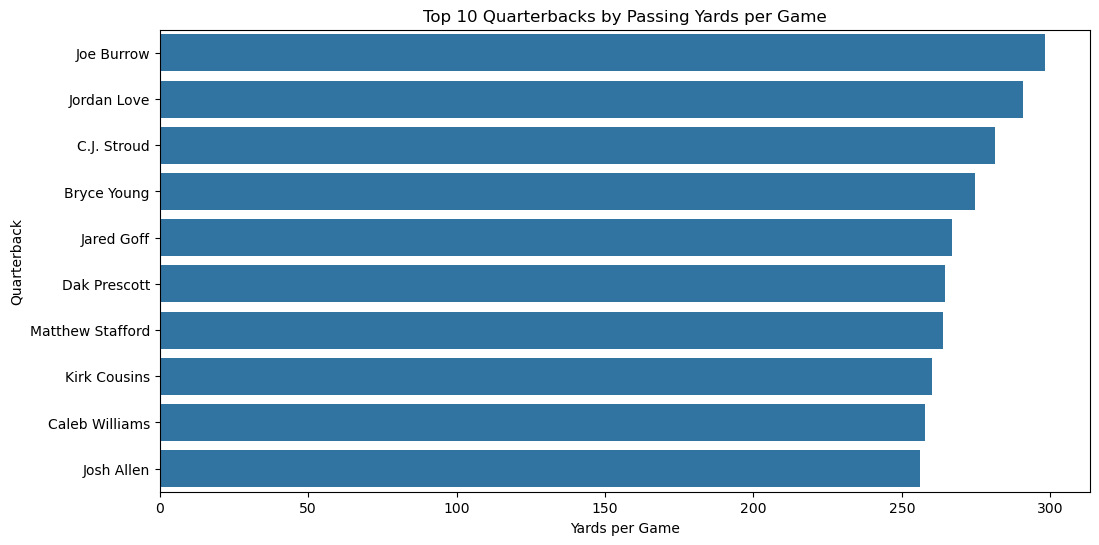

In [19]:
top10_ypg = df.nlargest(10, 'YDS/G')

plt.figure(figsize=(12, 6))
sns.barplot(data=top10_ypg, x='YDS/G', y='Name')

plt.title('Top 10 Quarterbacks by Passing Yards per Game')
plt.xlabel('Yards per Game')
plt.ylabel('Quarterback')
plt.grid(False)
plt.show()

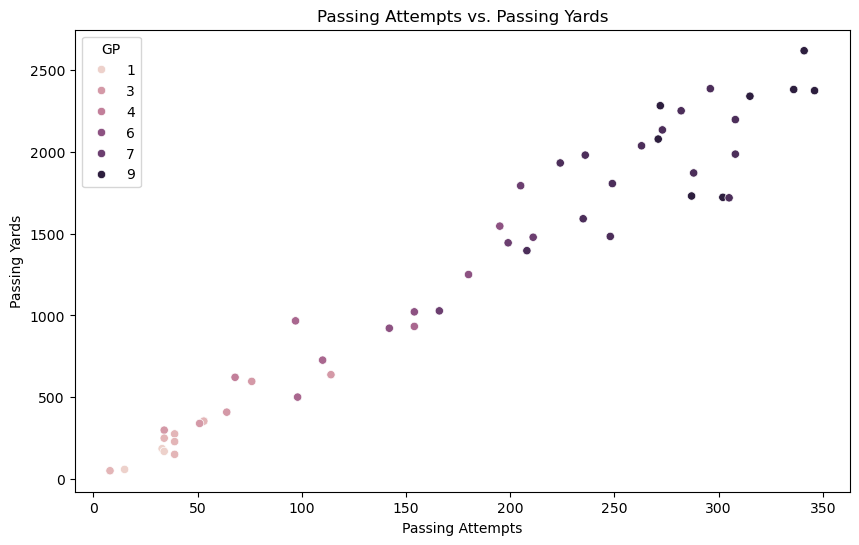

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='ATT', y='YDS',hue= 'GP')

plt.title('Passing Attempts vs. Passing Yards')
plt.xlabel('Passing Attempts')
plt.ylabel('Passing Yards')
plt.grid(False)
plt.show()

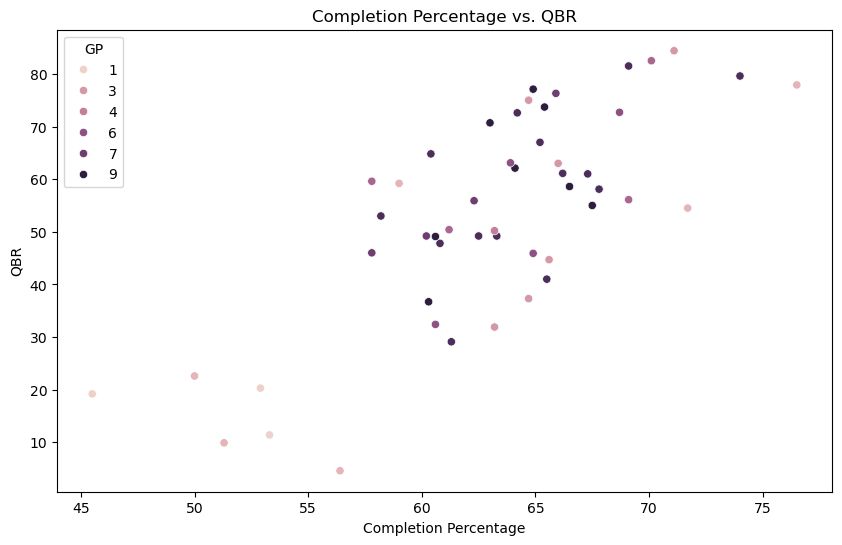

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='CMP%', y='QBR',hue='GP')

plt.title('Completion Percentage vs. QBR')
plt.xlabel('Completion Percentage')
plt.ylabel('QBR')
plt.grid(False)
plt.show()

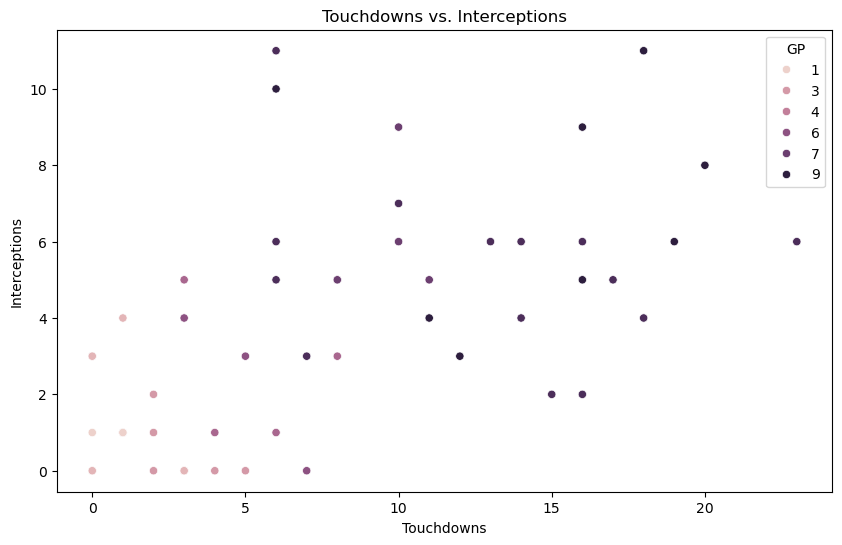

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='TD', y='INT',hue='GP')

plt.title('Touchdowns vs. Interceptions')
plt.xlabel('Touchdowns')
plt.ylabel('Interceptions')
plt.grid(False)
plt.show()

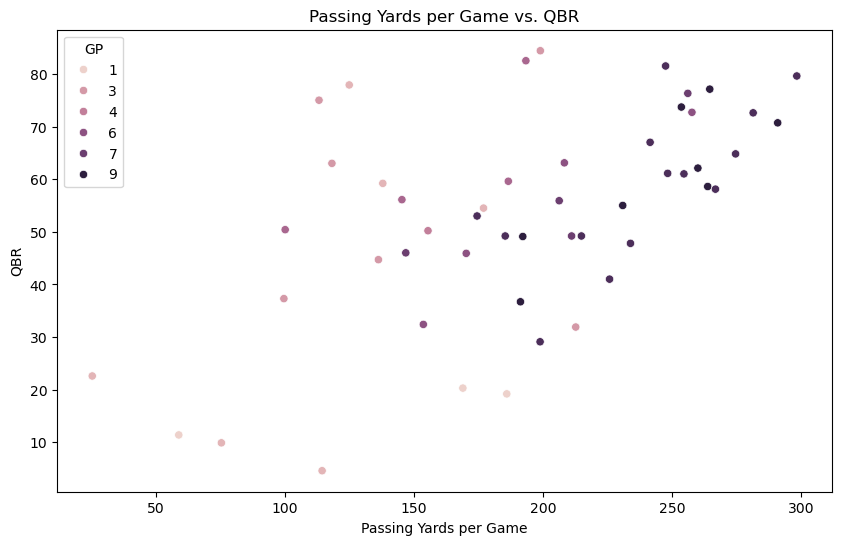

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='YDS/G', y='QBR',hue='GP')

plt.title('Passing Yards per Game vs. QBR')
plt.xlabel('Passing Yards per Game')
plt.ylabel('QBR')
plt.grid(False)
plt.show()

## Final EDA Summary

This project analyzed NFL quarterback statistics using data collected from ESPN. The final dataset contained 50 quarterbacks and 18 columns, with no missing values or duplicate rows.

Exploratory data analysis included descriptive statistics, histograms, boxplots, correlation analysis, and player comparisons.

**Key Findings:**
- Passing attempts and passing yards had a strong positive correlation (r = 0.97).
- Completion percentage and QBR were strongly positively correlated (r = 0.76).
- Several outliers were identified in completion percentage, yards per attempt, and QBR.
- Most outliers involved quarterbacks with limited playing time.

**Conclusion:**

Quarterback performance is influenced by both playing time and passing efficiency. Total passing statistics are useful for measuring production, while per-game averages and efficiency metrics allow for more meaningful comparisons. Further analysis could examine quarterbacks with similar playing time and investigate which statistics are most closely associated with QBR.

## Step 7: Feature Engineering

We will create two new features to evaluate quarterback passing efficiency:

- **TD_PCT:** Percentage of passing attempts resulting in touchdowns. Higher values indicate better touchdown efficiency.
- **INT_PCT:** Percentage of passing attempts resulting in interceptions. Lower values indicate better ball security.

These metrics allow us to compare quarterbacks with different passing attempt totals.

In [26]:
# Calculate touchdown percentage
df['TD_PCT'] =((df['TD'] / df['ATT']) * 100).round(2)

# Calculate interception percentage
df['INT_PCT'] = ((df['INT'] / df['ATT']) * 100).round(2)

# Display the new features alongside player information
df[['Name', 'TEAM', 'TD_PCT', 'INT_PCT']].head(10)

,Name,TEAM,TD_PCT,INT_PCT
0,Jordan Love,GB,5.57,1.76
1,Joe Burrow,CIN,7.77,2.03
2,Dak Prescott,DAL,4.76,1.49
3,Matthew Stafford,LAR,4.62,2.60
4,Kirk Cousins,LV,6.35,2.54
5,Drake Maye,NE,6.62,4.04
6,C.J. Stroud,HOU,5.67,0.71
7,Bryce Young,CAR,5.19,1.95
8,Jared Goff,DET,5.49,0.73
9,Geno Smith,NYJ,4.43,1.11


## Step 8: Feature Analysis

We will examine the relationship between touchdown percentage and interception percentage using a scatterplot.

The goal is to identify quarterbacks who produce touchdowns efficiently while minimizing interceptions.

- **Higher TD_PCT:** Better touchdown efficiency.
- **Lower INT_PCT:** Better ball security.
- **Ideal performance:** High touchdown percentage and low interception percentage.

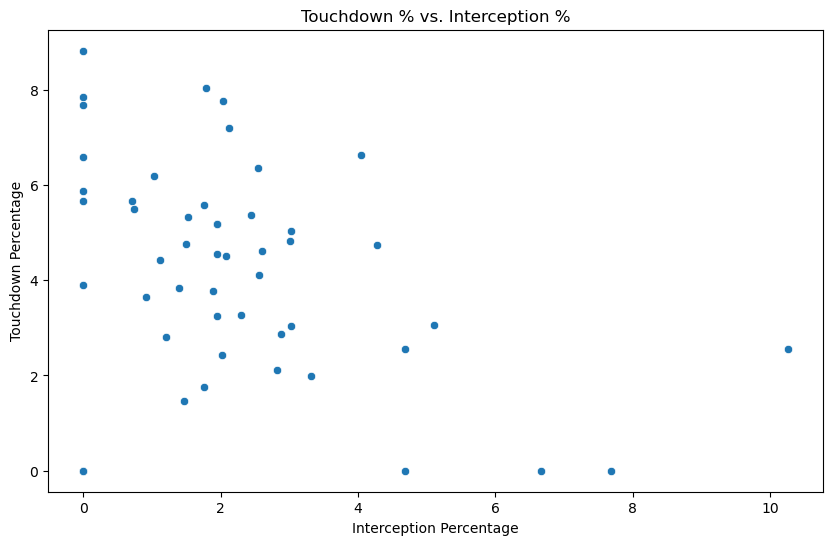

In [27]:
# Compare touchdown and interception percentages
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='INT_PCT', y='TD_PCT')

plt.title('Touchdown % vs. Interception %')
plt.xlabel('Interception Percentage')
plt.ylabel('Touchdown Percentage')
plt.grid(False)
plt.show()

In [28]:
df.nlargest(10, 'TD_PCT')[['Name', 'TEAM', 'GP', 'TD_PCT', 'INT_PCT']]

,Name,TEAM,GP,TD_PCT,INT_PCT
43,Jaxson Dart,NYG,2,8.82,0.00
13,Trevor Lawrence,JAX,8,8.04,1.79
40,Marcus Mariota,WSH,3,7.84,0.00
1,Joe Burrow,CIN,8,7.77,2.03
42,Carson Wentz,MIN,2,7.69,0.00
12,Brock Purdy,SF,8,7.20,2.12
5,Drake Maye,NE,9,6.62,4.04
35,Drew Lock,SEA,3,6.58,0.00
4,Kirk Cousins,LV,9,6.35,2.54
29,Lamar Jackson,BAL,5,6.19,1.03


## Step 9: Feature Selection

Feature selection involves choosing the variables used to train a machine learning model.

For this project, we will use passing efficiency statistics to predict quarterback QBR.

- **Target Variable (y):** QBR
- **Predictor Variables (X):** CMP%, AVG, YDS/G, TD_PCT, INT_PCT

We will exclude player names, teams, rankings, and QBR from our predictor variables.

**Note:** Since QBR is calculated using quarterback performance statistics, this model will estimate existing QBR rather than forecast future performance.

In [29]:
# Select the independent variables (features)
X = df[['CMP%', 'AVG', 'YDS/G', 'TD_PCT', 'INT_PCT']]

# Select the dependent variable (target)
y = df['QBR']

# Check the dimensions of our features and target
print('Features:', X.shape)
print('Target:', y.shape)

Features: (50, 5)
Target: (50,)


In [30]:
print('Missing Feature Values'.center(50, '='))

print(X.isna().sum())
print('\nMissing Target Values:', y.isna().sum())

==============Missing Feature Values==============
CMP%       0
AVG        0
YDS/G      0
TD_PCT     0
INT_PCT    0
dtype: int64

Missing Target Values: 0


In [31]:
print('Infinite Values:', np.isinf(X.to_numpy()).sum())

Infinite Values: 0


## Step 10: Train/Test Split

We will divide our dataset into training and testing sets to evaluate how well our machine learning model predicts quarterback QBR.

- **Training Set (80%):** Used to train the model.
- **Testing Set (20%):** Used to evaluate predictions on unseen data.
- **Random State (42):** Ensures reproducible results.

This helps us evaluate how well the model generalizes to quarterbacks not included in training.

In [32]:
from sklearn.model_selection import train_test_split

# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42)

# Display the dimensions of each dataset
print('Training Features:', X_train.shape)
print('Testing Features:', X_test.shape)
print('Training Target:', y_train.shape)
print('Testing Target:', y_test.shape)

Training Features: (40, 5)
Testing Features: (10, 5)
Training Target: (40,)
Testing Target: (10,)


## Step 11: Linear Regression Model

We will train a Linear Regression model to estimate quarterback QBR using passing statistics.

- **Algorithm:** Linear Regression
- **Features:** CMP%, AVG, YDS/G, TD_PCT, INT_PCT
- **Target:** QBR

Linear Regression identifies linear relationships between the predictor variables and the target variable.

The model will learn from the training data and generate predictions using the testing data.

In [34]:
from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

# Generate predictions using the testing data
y_pred = model.predict(X_test)

# Display the first five predictions
print('Predicted QBR:', y_pred[:5].round(2))
print('Actual QBR:', y_test.values[:5])

Predicted QBR: [74.88 70.18 49.02 24.66 48.42]
Actual QBR: [67.  54.5 59.6 19.2 49.1]


In [35]:
# Compare actual and predicted QBR
results = pd.DataFrame({
    'Actual QBR': y_test.values,
    'Predicted QBR': y_pred.round(2)})

results

,Actual QBR,Predicted QBR
0,67.0,74.88
1,54.5,70.18
2,59.6,49.02
3,19.2,24.66
4,49.1,48.42
5,11.4,7.87
6,63.1,56.87
7,53.0,40.20
8,56.1,56.77
9,49.2,48.77


## Step 12: Model Evaluation

We will evaluate our Linear Regression model using three performance metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted QBR. Lower is better.
- **RMSE (Root Mean Squared Error):** Measures prediction error while penalizing larger mistakes more heavily. Lower is better.
- **R² (Coefficient of Determination):** Measures how well the model explains variation in QBR. Values closer to 1 indicate a better fit.

These metrics help determine how accurately our model estimates quarterback performance on the testing dataset.

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate model evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display the results
print('Model Evaluation'.center(50, '='))

print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R² Score: {r2:.4f}')

=================Model Evaluation=================
MAE: 6.39
RMSE: 8.16
R² Score: 0.7801


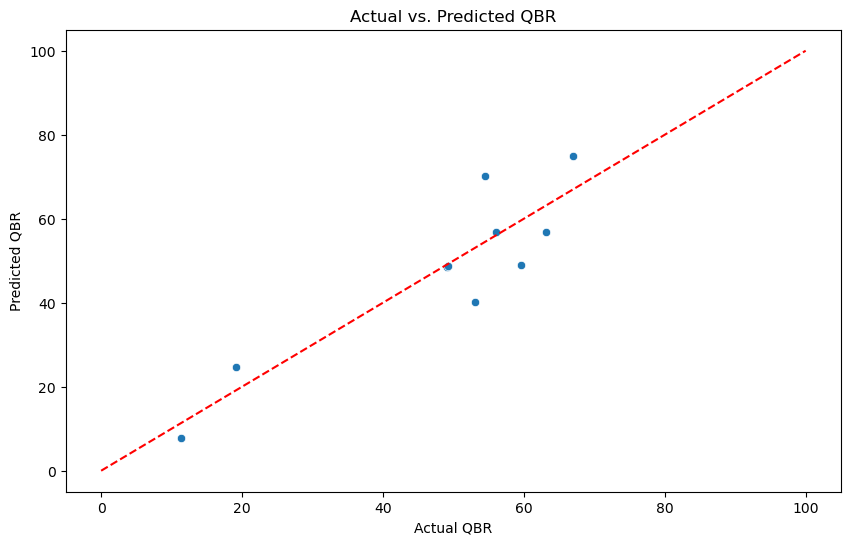

In [39]:
# Visualize actual vs. predicted QBR
plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_test, y=y_pred)

# Add a reference line for perfect predictions
plt.plot([0, 100], [0, 100], 'r--')

plt.title('Actual vs. Predicted QBR')
plt.xlabel('Actual QBR')
plt.ylabel('Predicted QBR')
plt.grid(False)
plt.show()

### Model Evaluation Results

The Linear Regression model demonstrated promising performance on the testing dataset.

- **MAE:** 6.39 QBR points
- **RMSE:** 8.16 QBR points
- **R²:** 0.7801 (78.01%)

The model explained approximately 78% of the variation in QBR, with an average prediction error of 6.39 points.

The scatterplot shows that most predictions were reasonably close to the actual values, although some larger errors occurred.

Overall, the results suggest that passing statistics are useful for estimating QBR. However, additional validation is needed because the testing dataset contains only 10 quarterbacks.

## Step 13: Cross-Validation

We will use 5-fold cross-validation to evaluate the consistency of our Linear Regression model.

- **5 Folds:** Divide the training data into five groups.
- **Training:** Train the model using four groups.
- **Validation:** Evaluate the model using the remaining group.
- **Repetition:** Repeat five times, changing the validation group.

We will calculate the average R², MAE, and RMSE to evaluate model performance across different data splits.

In [40]:
from sklearn.model_selection import cross_validate, KFold

# Create 5 reproducible folds
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate our model using training data only
scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'])

# Calculate average performance
print('Cross-Validation Results'.center(50, '='))

print(f"Average R²: {scores['test_r2'].mean():.4f}")
print(f"Average MAE: {-scores['test_neg_mean_absolute_error'].mean():.2f}")
print(f"Average RMSE: {-scores['test_neg_root_mean_squared_error'].mean():.2f}")

=============Cross-Validation Results=============
Average R²: 0.5591
Average MAE: 9.65
Average RMSE: 11.61



### Cross-Validation Results

The Linear Regression model achieved the following average cross-validation scores:

- **R²:** 0.5591
- **MAE:** 9.65
- **RMSE:** 11.61

Cross-validation performance was lower than the original test results (R² = 0.7801, MAE = 6.39, RMSE = 8.16).

This suggests that model performance varies across different groups of quarterbacks. The small dataset may contribute to this variability.

Overall, the model demonstrates some predictive ability, but additional validation and improvements are needed.


In [41]:
# Display Linear Regression coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print('Model Coefficients'.center(50, '='))
print(coefficients)

================Model Coefficients================
   Feature  Coefficient
0     CMP%     1.155827
1      AVG     1.612238
2    YDS/G     0.053355
3   TD_PCT     3.546693
4  INT_PCT    -1.522022


### Model Coefficient Interpretation

The Linear Regression model identified positive relationships between QBR and completion percentage, yards per attempt, yards per game, and touchdown percentage.

Interception percentage had a negative relationship with predicted QBR.

- **TD_PCT:** A one-percentage-point increase was associated with a 3.55-point increase in predicted QBR.
- **INT_PCT:** A one-percentage-point increase was associated with a 1.52-point decrease in predicted QBR.
- **CMP%, AVG, and YDS/G:** All had positive coefficients.

These relationships assume other variables remain constant. Coefficient magnitudes cannot be directly compared because the features have different scales.

Overall, the results suggest that passing efficiency metrics contribute to estimating quarterback QBR.

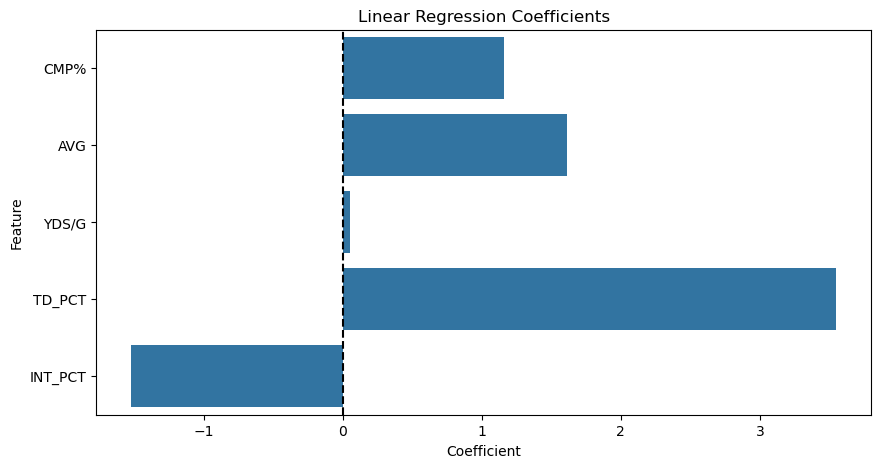

In [42]:
# Visualize model coefficients
plt.figure(figsize=(10, 5))

sns.barplot(data=coefficients, x='Coefficient', y='Feature')

plt.axvline(0, color='black', linestyle='--')
plt.title('Linear Regression Coefficients')
plt.grid(False)
plt.show()


## Step 15: Model Improvement — Ridge Regression

We will compare Ridge Regression against our original Linear Regression model.

Ridge Regression uses L2 regularization to reduce large coefficients and potentially improve model generalization.

**Objectives:**
- Train a Ridge Regression model.
- Standardize our features using StandardScaler.
- Evaluate performance using 5-fold cross-validation.
- Compare Ridge Regression against Linear Regression.

The goal is to determine whether regularization improves prediction accuracy and model stability.


In [43]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create Ridge Regression with feature scaling
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train Ridge Regression using training data
ridge_model.fit(X_train, y_train)

# Predict QBR on the test dataset
ridge_pred = ridge_model.predict(X_test)

# Evaluate Ridge Regression
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print('Ridge Regression Results'.center(50, '='))

print(f'MAE: {ridge_mae:.2f}')
print(f'RMSE: {ridge_rmse:.2f}')
print(f'R² Score: {ridge_r2:.4f}')

=============Ridge Regression Results=============
MAE: 6.34
RMSE: 8.07
R² Score: 0.7849


In [44]:
# Compare both regression models
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression'],
    'MAE': [mae, ridge_mae],
    'RMSE': [rmse, ridge_rmse],
    'R²': [r2, ridge_r2]
})

comparison.round(4)

,Model,MAE,RMSE,R²
0,Linear Regression,6.3936,8.1602,0.7801
1,Ridge Regression,6.3392,8.0698,0.7849


In [45]:
# Evaluate Ridge using the same 5 folds
ridge_scores = cross_validate(
    ridge_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error']
)

# Display average cross-validation results
print('Ridge Cross-Validation'.center(50, '='))

print(f"Average R²: {ridge_scores['test_r2'].mean():.4f}")
print(f"Average MAE: {-ridge_scores['test_neg_mean_absolute_error'].mean():.2f}")
print(f"Average RMSE: {-ridge_scores['test_neg_root_mean_squared_error'].mean():.2f}")

==============Ridge Cross-Validation==============
Average R²: 0.5740
Average MAE: 9.51
Average RMSE: 11.45


### Ridge Regression Results
Ridge Regression slightly outperformed Linear Regression across all evaluation metrics.

**Test Set Results:**
- **MAE:** Improved from 6.39 to 6.34
- **RMSE:** Improved from 8.16 to 8.07
- **R²:** Increased from 0.7801 to 0.7849

**Cross-Validation Results:**
- **Average R²:** Improved from 0.5591 to 0.5740
- **Average MAE:** Decreased from 9.65 to 9.51
- **Average RMSE:** Decreased from 11.61 to 11.45

Ridge Regression demonstrated slightly better performance, suggesting that regularization may help improve model generalization.

However, the improvements were small, and further testing would be needed to confirm their consistency.

In [46]:
from sklearn.model_selection import GridSearchCV

# Define alpha values to test
parameters = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100]
}

# Create GridSearchCV
grid = GridSearchCV(
    ridge_model,
    parameters,
    cv=cv,
    scoring='neg_mean_squared_error'
)

# Train using the training dataset
grid.fit(X_train, y_train)

# Display the best parameters
print('Best Alpha:', grid.best_params_)
print(f'Best CV RMSE: {np.sqrt(-grid.best_score_):.2f}')

Best Alpha: {'ridge__alpha': 10}
Best CV RMSE: 11.24


In [47]:
# Get the best Ridge model
best_ridge = grid.best_estimator_

# Generate predictions
best_pred = best_ridge.predict(X_test)

# Calculate evaluation metrics
best_mae = mean_absolute_error(y_test, best_pred)
best_rmse = np.sqrt(mean_squared_error(y_test, best_pred))
best_r2 = r2_score(y_test, best_pred)

# Compare results
comparison = pd.DataFrame({
    'Model': ['Linear', 'Ridge', 'Tuned Ridge'],
    'MAE': [mae, ridge_mae, best_mae],
    'RMSE': [rmse, ridge_rmse, best_rmse],
    'R²': [r2, ridge_r2, best_r2]
})

comparison.round(4)

,Model,MAE,RMSE,R²
0,Linear,6.3936,8.1602,0.7801
1,Ridge,6.3392,8.0698,0.7849
2,Tuned Ridge,5.8246,7.5181,0.8133



### Hyperparameter Tuning Results

GridSearchCV identified **alpha = 10** as the best Ridge Regression regularization strength.

**Tuned Ridge Performance:**
- **MAE:** 5.82
- **RMSE:** 7.52
- **R²:** 0.8133
- **Best Cross-Validation RMSE:** 11.24

The tuned Ridge model outperformed both the original Linear Regression and untuned Ridge Regression models on the test set.

These results suggest that stronger regularization improved model performance. However, the small dataset and repeated test-set comparisons limit how confidently these results can be generalized.

Overall, tuned Ridge Regression was the best-performing model evaluated in this project.


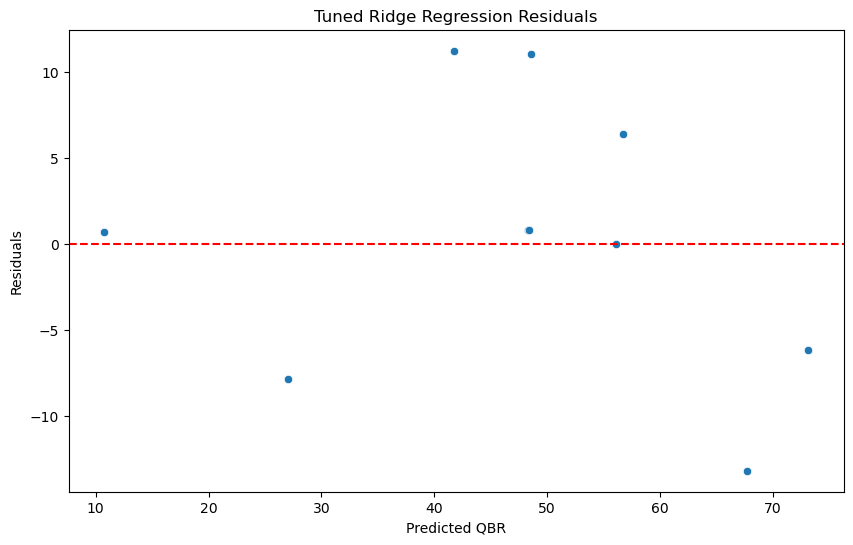

In [48]:
# Calculate residuals
residuals = y_test - best_pred

# Visualize residuals
plt.figure(figsize=(10, 6))

sns.scatterplot(x=best_pred, y=residuals)

plt.axhline(0, color='red', linestyle='--')
plt.title('Tuned Ridge Regression Residuals')
plt.xlabel('Predicted QBR')
plt.ylabel('Residuals')
plt.grid(False)
plt.show()


### Residual Analysis Results

The tuned Ridge Regression residual plot shows errors distributed above and below zero without an obvious systematic pattern.

- Positive residuals indicate underestimated QBR.
- Negative residuals indicate overestimated QBR.
- Several predictions were close to the actual values.
- A few residuals exceeded 10 QBR points in magnitude.

Overall, the model demonstrates reasonable prediction accuracy, although some larger errors remain. The small testing dataset limits our ability to draw stronger conclusions.

## Step 18: Final Project Conclusion

### Project Summary

This project analyzed NFL quarterback statistics collected from ESPN using Python. The objective was to explore quarterback performance, identify important statistical relationships, and develop a machine learning model to estimate QBR.

The dataset contained **50 quarterbacks and 18 original columns**, with no missing values or duplicate rows.

### Key Findings

- Passing attempts and passing yards demonstrated a strong positive correlation (r = 0.97).
- Completion percentage and QBR were strongly positively correlated (r = 0.76).
- Several outliers were identified, primarily among quarterbacks with limited playing time.
- Feature engineering introduced touchdown percentage and interception percentage to measure passing efficiency.

### Machine Learning Results

Three regression models were evaluated:

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 6.39 | 8.16 | 0.7801 |
| Ridge Regression | 6.34 | 8.07 | 0.7849 |
| Tuned Ridge Regression | **5.82** | **7.52** | **0.8133** |

**Tuned Ridge Regression (alpha = 10)** achieved the best test-set performance, explaining approximately 81.3% of the variation in QBR.

Cross-validation results were weaker, suggesting that model performance varies depending on the training and validation observations.

### Project Limitations

- The dataset contained only 50 quarterbacks.
- The testing dataset included approximately 10 observations.
- Quarterbacks had different amounts of playing time.
- The model estimated existing QBR rather than future quarterback performance.
- Multiple model comparisons were performed using the same test set, limiting the reliability of the final performance estimate.

### Future Improvements

1. Collect quarterback statistics from multiple NFL seasons.
2. Increase the number of observations to improve model reliability.
3. Explore additional features such as sack rate and touchdown-to-interception ratio.
4. Compare additional algorithms, including Random Forest and Gradient Boosting.
5. Use historical statistics to predict future-season performance.

### Final Conclusion

The project demonstrated how data preprocessing, exploratory data analysis, feature engineering, and machine learning can be used to analyze NFL quarterback performance.

Tuned Ridge Regression produced the strongest test-set results, showing that passing efficiency statistics can help estimate QBR.

Although the model showed promising performance, additional data and validation would be necessary before using it for reliable predictions.